In [1]:
import gymnasium as gym

import numpy as np
import time
import matplotlib.pyplot as plt
import random 
import numpy as np
from collections import defaultdict
 
 

env=gym.make('CartPole-v1')#,render_mode='human')

(state,_)=env.reset()

In [2]:
def treatState(state):
    state[0]=np.digitize(state[0],pos_space)
    state[1]=np.digitize(state[1],vel_space)
    state[2]=np.digitize(state[2],ang_space)
    state[3]=np.digitize(state[3],ang_vel_space)
    return state

In [3]:
def findTrainGoal(goal,epsilon):# par estimation general
    newGoal= (12877*epsilon**2 - 16810*epsilon - 100 * goal +7233)/(45*epsilon**2 + 22*epsilon -53)
    return int(newGoal)

In [4]:
def findTrainGoal2(goal,epsilon):# par estimation individuel
    dictGoals={
        90 : 77.12*epsilon**2 + -174.08*epsilon + 117.97,
        100:  74.28*epsilon**2 + -179.97*epsilon + 124.63,
        110: 111.41* epsilon**2 + -225.16*epsilon + 133.10,
        120: 91.42*epsilon**2 + -204.90*epsilon + 131.42,
        130: 32.28*epsilon**2 + -179.16*epsilon + 156.93,
        140: 74.73*epsilon**2 + -193.67*epsilon + 136.07
    }
    dist=10000000
    newgoal=0
    for x,y in dictGoals.items():
        if abs(goal - y) < dist:
            dist = abs(goal - y)
            newgoal=x
    return newgoal

In [5]:
class Qlearning():

    def __init__(self, epsilon, gamma, alpha, num_actions):

   
        self.epsilon = epsilon
        self.gamma = gamma
        self.alpha = alpha
        self.Qvalues = defaultdict(lambda : np.repeat(0.0,num_actions))
        self.num_actions=num_actions
        

    def getQvalue(self, state, action):
        return self.Qvalues[state][action]

    
    """
    Compute the action to take in the current state.  With
    probability self.epsilon, we should take a random action and
    take the best policy action otherwise.  Note that if there are
    no legal actions, which is the case at the terminal state, you
    should choose None as the action.
    """
    def getAction(self, state):
        if random.random() < self.epsilon:
          return random.randint(0,self.num_actions-1)
        else:
          return np.argmax(self.Qvalues[state])
    
    """    
    update the qV of one state action with the knowledge of the reward
    """
    def update(self, state, action, nextState, reward):
      self.Qvalues[state][action] = self.getQvalue(state, action) + self.alpha * (reward + self.gamma * np.max(self.Qvalues[nextState])-  self.getQvalue(state, action))
        
    def _update_Q_table(self, Q, state, action, reward, next_state, Qp, num_agents):
        Q[state][action] = (1 - self.alpha) * Q[state][action] + self.alpha * (reward + self.gamma * 1/num_agents * np.max(Qp[next_state]))

    def increasing_reward(self,value):
        result=0
    
        if(value<0):
            for i in range(0,value,-1):
                result +=i
        else:
            for i in range(0,value):
                result +=i
        return result
    def episodeRewards(self,episodes,goal):
        result=len(episodes)
        reward=self.increasing_reward(goal - abs(goal-result))
        
            
        for i in range(len(episodes)-1,-1,-1):
            self.update(episodes[i][0],episodes[i][1],episodes[i][2],reward)
            reward*=self.gamma
        

### learner rewards

### Test

In [6]:
episodeNumber=30000
timeSteps=10000
episodesResults=[]
episodesTestResults=[]
episodesTestResultsDeviation=[]
numberOfTest=50
qagent= Qlearning(0.1,0.99,0.1,2)
pos_space=np.linspace(-2.4,2.4,10)
vel_space=np.linspace(4,4,10)
ang_space=np.linspace(-0.2095,0.2095,10)
ang_vel_space=np.linspace(-4,4,10)

In [7]:
goal=findTrainGoal(130,0.2)

In [8]:
for episodeIndex in range(episodeNumber):
   
    state,_=env.reset()
    state=treatState(state)
    #print("episode: ",episodeIndex)
    episodeObservation=[]
    for timeIndex in range(timeSteps):
        action=qagent.getAction(tuple(state))
        next_state, reward, terminated, truncated, info =env.step(action)
        next_state=treatState(next_state)
        episodeObservation.append([tuple(state),action,tuple(next_state)])
        #qagent.update(tuple(state),action,tuple(next_state),reward)
        state=next_state
        if (terminated):
            #print("Number of steps :",timeIndex)
            
            episodesResults.append(timeIndex)
            break

    qagent.episodeRewards(episodeObservation,goal)
    if(episodeIndex %500 ==0):
        print(episodeIndex)
        qagent.epsilon=0
        testResultList=[]
        for episodeIndex in range(numberOfTest):
    
            state,_=env.reset()
            state=treatState(state)
            for timeIndex in range(timeSteps):
                action=qagent.getAction(tuple(state))
                next_state, reward, terminated, truncated, info =env.step(action)
                next_state=treatState(next_state)
                state=next_state
                if (terminated):
                    testResultList.append(timeIndex)
                    break

        episodesTestResults.append(sum(testResultList)/len(testResultList))
        episodesTestResultsDeviation.append(np.std(episodesTestResults))
        qagent.epsilon=0.1
    


env.close() 

0
500
1000
1500
2000
2500
3000
3500
4000
4500
5000
5500
6000
6500
7000
7500
8000
8500
9000
9500
10000
10500
11000
11500
12000
12500
13000
13500
14000
14500
15000
15500
16000
16500
17000
17500
18000
18500
19000
19500
20000
20500
21000
21500
22000
22500
23000
23500
24000
24500
25000
25500
26000
26500
27000
27500
28000
28500
29000
29500


147.65093333333334


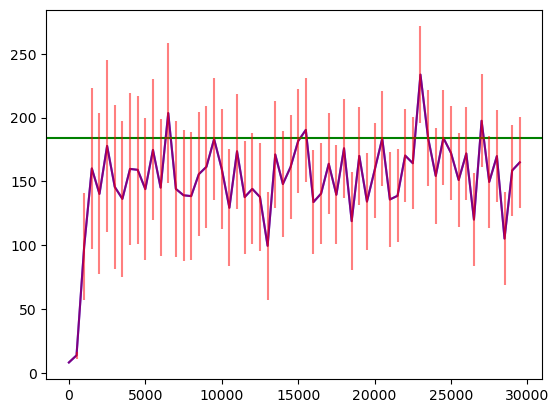

In [9]:
x=[]
for i in range(len(episodesTestResults)):
    x.append(i*500)
plt.plot(x,episodesTestResults,color ='b')
plt.axhline(y= goal,color ='g')
plt.errorbar(x,episodesTestResults,yerr=episodesTestResultsDeviation,color ='r',alpha=0.5)
#plt.savefig("SVG/GoalIncrease1.svg")
print(sum(episodesResults)/len(episodesResults))

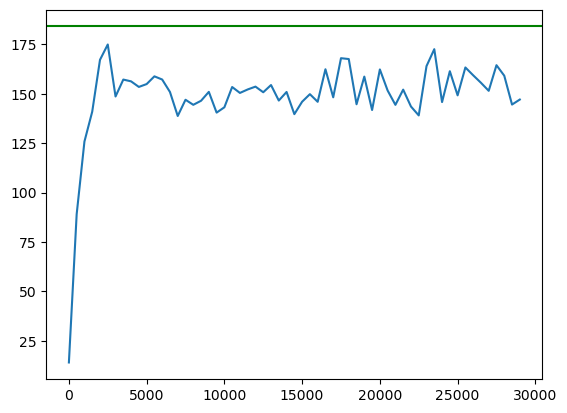

In [10]:
previous100AveragePlot=[]
for i in range(1,len(episodesTestResults)):
    previous100AveragePlot.append(sum(episodesResults[(i*500)-100:(i*500)])/100)
x=[]
for i in range(len(previous100AveragePlot)):
    x.append(i*500)
plt.plot(x,previous100AveragePlot)
plt.axhline(y= goal,color ='g')
#plt.savefig("SVG/GoalIncrease2.svg")

1175


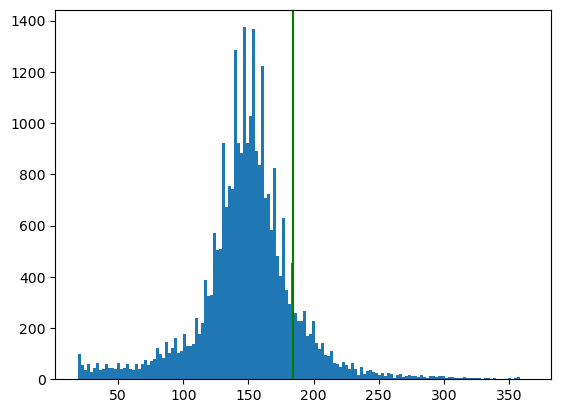

In [11]:
#histogram
episodesResultswithoutOutliers=[]
for i in episodesResults:
    if i >goal * 0.1 and i < goal*2:
        episodesResultswithoutOutliers.append(i)
plt.hist(episodesResultswithoutOutliers,bins=150)
plt.axvline(x= goal,color ='g')
#plt.savefig("SVG/GoalIncrease3.svg")
print(len(episodesResults)-len(episodesResultswithoutOutliers))

1175


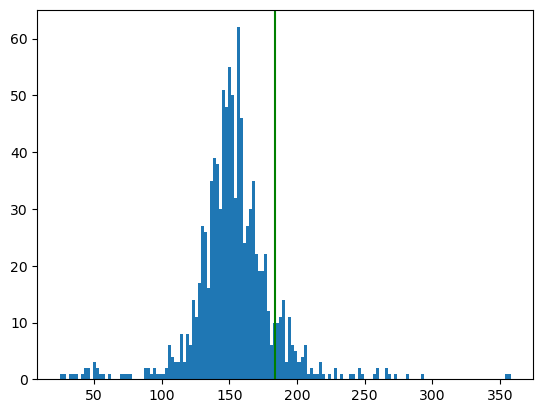

In [12]:
episodesResultswithoutOutliers=[]
for i in episodesResults:
    if i >goal * 0.1 and i < goal*2:
        episodesResultswithoutOutliers.append(i)
plt.hist(episodesResultswithoutOutliers[-1000:],bins=150)
plt.axvline(x= goal,color ='g')
#plt.savefig("SVG/GoalIncrease4.svg")
print(len(episodesResults)-len(episodesResultswithoutOutliers))

In [13]:
goal2LearnerEp=episodesResults
%store goal2LearnerEp
goal2learnerTestEp=episodesTestResults
%store goal2learnerTestEp
print(np.mean(episodesResults[-1000:]))
print(np.std(episodesResults[-1000:]))

Stored 'goal2LearnerEp' (list)
Stored 'goal2learnerTestEp' (list)
152.84
43.586539206502735


148.38
29.120295328172755


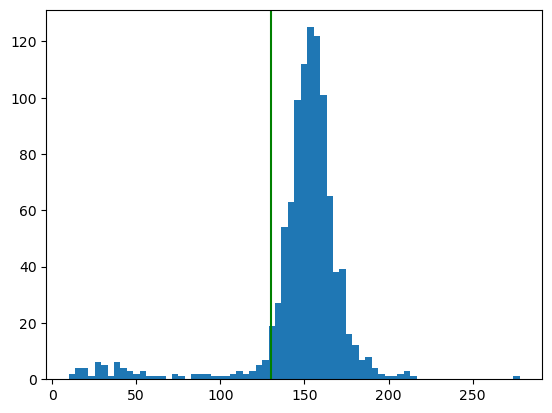

In [14]:
qagent.epsilon=0.2
last1000testList=[]
for episodeIndex in range(1000):
    
    state,_=env.reset()
    state=treatState(state)
    for timeIndex in range(timeSteps):
        action=qagent.getAction(tuple(state))
        next_state, reward, terminated, truncated, info =env.step(action)
        next_state=treatState(next_state)
        state=next_state
        if (terminated):
            last1000testList.append(timeIndex)
            break



episodesResultswithoutOutliers=[]
for i in last1000testList:
    if i >0 and i < 1000:
        episodesResultswithoutOutliers.append(i)
plt.hist(episodesResultswithoutOutliers,bins=70)
plt.axvline(x= 130,color ='g')
#plt.savefig("SVG/GoalIncreasedRand150.svg")
print(np.mean(last1000testList))
print(np.std(last1000testList))

In [15]:
last1000testList2=last1000testList
%store last1000testList2

Stored 'last1000testList2' (list)


In [16]:
def uniTest(agent,epsilon=0):
    agent.epsilon=epsilon
    last1000testList=[]
    for episodeIndex in range(1000):
    
        state,_=env.reset()
        state=treatState(state)
        for timeIndex in range(timeSteps):
            action=agent.getAction(tuple(state))
            next_state, reward, terminated, truncated, info =env.step(action)
            next_state=treatState(next_state)
            state=next_state
            if (terminated):
                last1000testList.append(timeIndex)
                break
    return np.mean(last1000testList),np.std(last1000testList)


In [17]:
import time
qagent.epsilon=0.2
env = gym.make("CartPole-v1", render_mode="human")
for episodeIndex in range(1):

    state,_=env.reset()
    state=treatState(state)
    for timeIndex in range(timeSteps):
        env.render()
        action=qagent.getAction(tuple(state))
        
        next_state, reward, terminated, truncated, info =env.step(action)
        next_state=treatState(next_state)
        state=next_state
        
        if (terminated):
            print(timeIndex)
            break
        time.sleep(0.02)
env.close()

157
